In [17]:
import json
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping


2025-05-12 21:26:34.842799: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-12 21:26:34.842831: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


In [3]:
# Load the preprocessed dataset
df = pd.read_csv('Edge-IIoTset_DNN-112.csv')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1945449 entries, 0 to 1945448
Data columns (total 99 columns):
 #   Column                     Dtype  
---  ------                     -----  
 0   arp.opcode                 float64
 1   arp.hw.size                float64
 2   icmp.checksum              float64
 3   icmp.seq_le                float64
 4   icmp.transmit_timestamp    float64
 5   http.content_length        float64
 6   http.response              float64
 7   tcp.ack                    float64
 8   tcp.ack_raw                float64
 9   tcp.checksum               float64
 10  tcp.connection.fin         float64
 11  tcp.connection.rst         float64
 12  tcp.connection.syn         float64
 13  tcp.connection.synack      float64
 14  tcp.dstport                float64
 15  tcp.flags                  float64
 16  tcp.flags.ack              float64
 17  tcp.len                    float64
 18  tcp.seq                    float64
 19  udp.port                   float64
 20  ud

In [5]:
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_TCP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_UDP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_HTTP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_ICMP', 'DDoS')

df['Attack_type'] = df['Attack_type'].str.replace('Port_Scanning', 'Scanning')
df['Attack_type'] = df['Attack_type'].str.replace('Fingerprinting', 'Scanning')
df['Attack_type'] = df['Attack_type'].str.replace('Vulnerability_scanner', 'Scanning')

df['Attack_type'] = df['Attack_type'].str.replace('MITM', 'MITM')

df['Attack_type'] = df['Attack_type'].str.replace('XSS', 'Injection')
df['Attack_type'] = df['Attack_type'].str.replace('SQL_injection', 'Injection')
df['Attack_type'] = df['Attack_type'].str.replace('Uploading', 'Injection')

df['Attack_type'] = df['Attack_type'].str.replace('Backdoor', 'Malware')
df['Attack_type'] = df['Attack_type'].str.replace('Password', 'Malware')
df['Attack_type'] = df['Attack_type'].str.replace('Ransomware', 'Malware')

In [6]:
print(df['Attack_type'].value_counts())

Attack_type
Normal       1399624
DDoS          288112
Injection     102851
Malware        83648
Scanning       70856
MITM             358
Name: count, dtype: int64


In [7]:
# Creating a dictionary of Types
attacks = {'Normal':0, 'DDoS':1, 'Scanning':2, 'Injection':3, 'MITM':4, 'Malware':5}
df['Attack_type'] = df['Attack_type'].map(attacks)

In [8]:
X = df.drop(columns=['Attack_label', 'Attack_type'])
y = df['Attack_type']

In [9]:
print(df['Attack_type'].value_counts())

Attack_type
0    1399624
1     288112
3     102851
5      83648
2      70856
4        358
Name: count, dtype: int64


In [10]:
# Apply the Chi-Squared test
chi_selector = SelectKBest(chi2, k='all')  # Set k to the desired number of features
X_kbest = chi_selector.fit_transform(X, y)

In [11]:
# Get the scores for each feature
chi_scores = chi_selector.scores_

# Combine scores with feature names
chi_scores = pd.DataFrame({'feature': X.columns, 'score': chi_scores})

# Sort the features by their scores
chi_scores = chi_scores.sort_values(by='score', ascending=False)

print(chi_scores)

                    feature         score
8               tcp.ack_raw  3.090813e+14
7                   tcp.ack  1.448397e+14
18                  tcp.seq  7.310286e+12
20               udp.stream  9.184477e+11
4   icmp.transmit_timestamp  1.689471e+11
..                      ...           ...
89                  mqtt1_8  1.169939e+00
84                  mqtt1_3  7.799595e-01
85                  mqtt1_4  7.799595e-01
90                  mqtt1_9  7.799595e-01
91                 mqtt1_10  7.799595e-01

[97 rows x 2 columns]


/tmp/ipykernel_22656/4000908500.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=chi_scores_top, x='score', y='feature', palette='Blues_r')


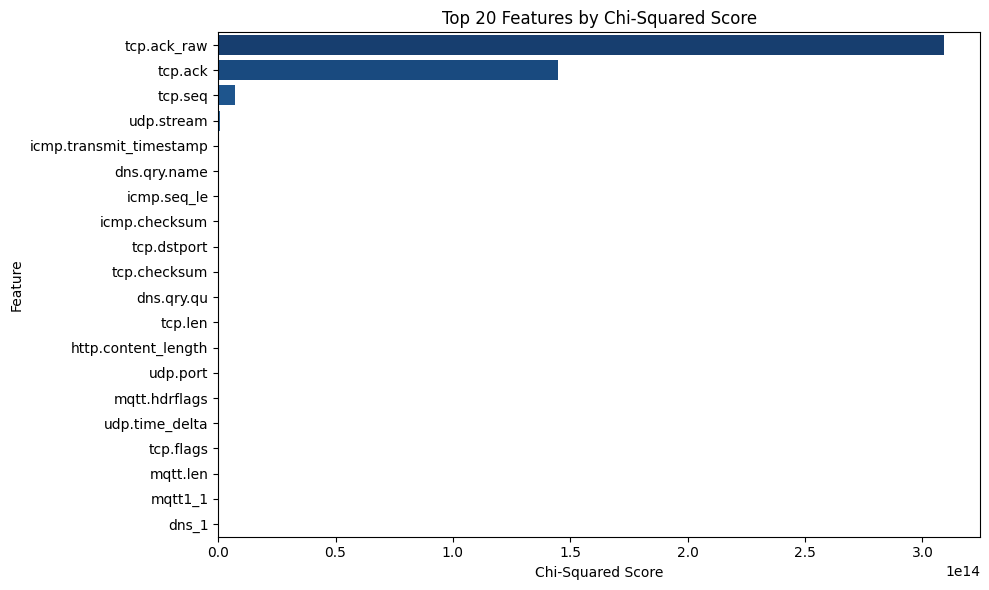

In [25]:
chi_scores_top = chi_scores.head(20)
plt.figure(figsize=(10, 6))
sns.barplot(data=chi_scores_top, x='score', y='feature', palette='Blues_r')
plt.title(f"Top 20 Features by Chi-Squared Score")
plt.xlabel("Chi-Squared Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

/tmp/ipykernel_22656/496316430.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=chi_scores_top, x='score', y='feature', palette='Blues_r')


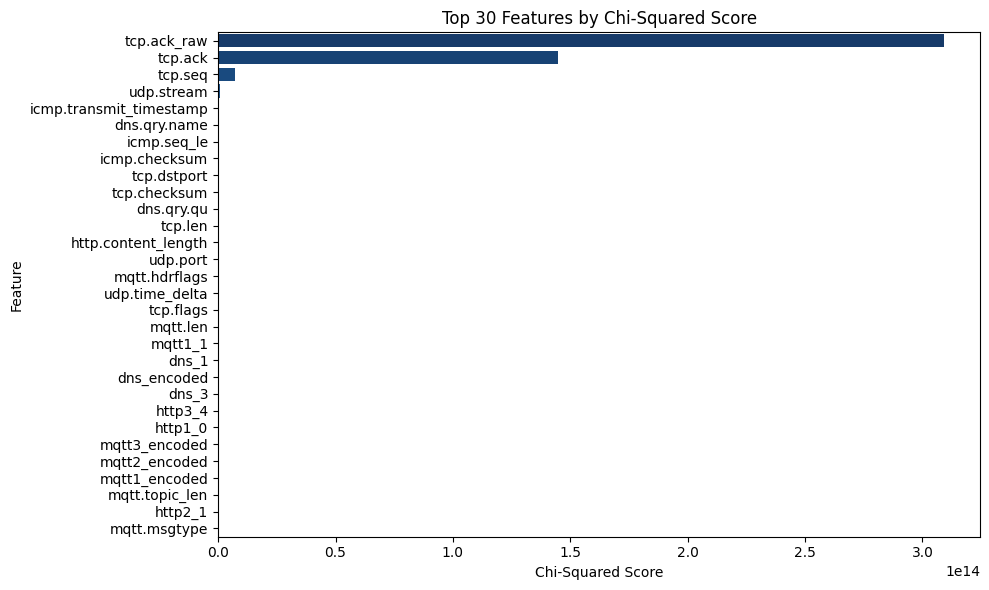

In [26]:
chi_scores_top = chi_scores.head(30)
plt.figure(figsize=(10, 6))
sns.barplot(data=chi_scores_top, x='score', y='feature', palette='Blues_r')
plt.title(f"Top 30 Features by Chi-Squared Score")
plt.xlabel("Chi-Squared Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

/tmp/ipykernel_22656/2188580838.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=chi_scores_top, x='score', y='feature', palette='Blues_r')


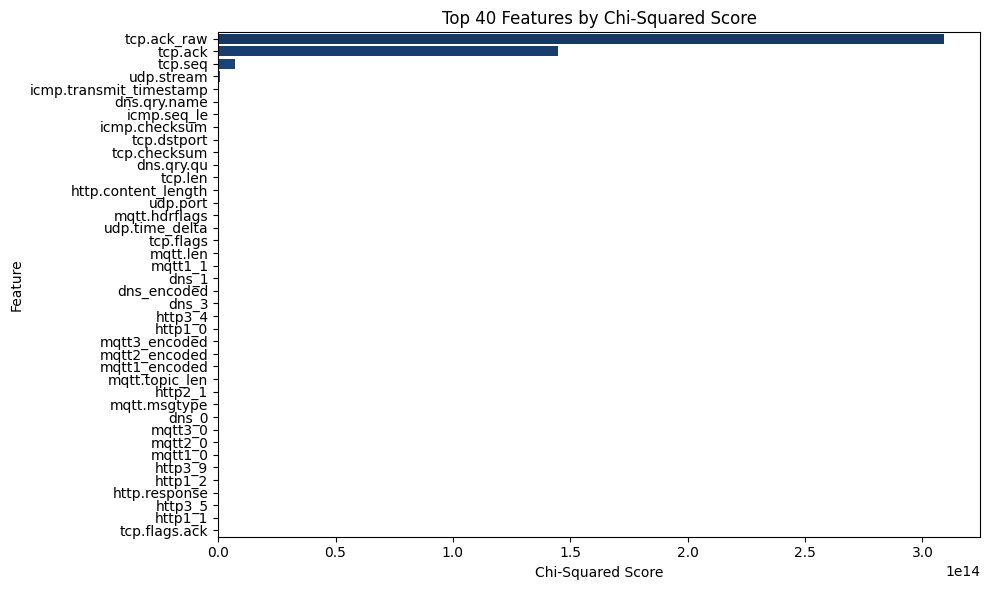

In [27]:
chi_scores_top = chi_scores.head(40)
plt.figure(figsize=(10, 6))
sns.barplot(data=chi_scores_top, x='score', y='feature', palette='Blues_r')
plt.title(f"Top 40 Features by Chi-Squared Score")
plt.xlabel("Chi-Squared Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [12]:
best_params = {
    "filters": 64,
    "kernel_size": 5,
    "dropout_rate": 0.3,
    "learning_rate": 0.0005,
    "l2_reg": 0.0001,
}

best_fit_params = {
    "batch_size": 32,
    "epochs": 25,
}

In [13]:
# Initialize the 1D CNN classifier
def model_1d_cnn(
        input_shape,
        num_classes=6,
        filters=64,
        kernel_size=3,
        pool_size=2,
        dropout_rate=0.5,
        dense_units=100,
        learning_rate=1e-3,
        optimizer="adam",
        l2_reg=0.0,
):
    _model = Sequential([
        Conv1D(filters=filters,
               kernel_size=kernel_size,
               activation="relu",
               kernel_regularizer=l2(l2_reg),
               input_shape=input_shape),
        MaxPooling1D(pool_size=pool_size),
        Dropout(dropout_rate),
        Flatten(),
        Dense(dense_units, activation="relu"),
    ])

    if num_classes == 2:
        _model.add(Dense(1, activation="sigmoid"))
        loss = "binary_crossentropy"
    else:
        _model.add(Dense(num_classes, activation="softmax"))
        loss = "sparse_categorical_crossentropy"

    # choose optimiser
    if optimizer == "adam":
        opt = Adam(learning_rate=learning_rate)
    elif optimizer == "rmsprop":
        opt = RMSprop(learning_rate=learning_rate)
    elif optimizer == "sgd":
        opt = SGD(learning_rate=learning_rate, momentum=0.9)
    else:
        raise ValueError("Unknown optimiser.")

    _model.compile(optimizer=opt, loss=loss, metrics=["accuracy"])
    return _model

In [14]:
max_features = len(chi_scores['feature'].tolist())
feature_counts = list(range(10, max_features + 1, 10))  # e.g., 10, 20, ..., up to all features

results = []
num_classes = 6
for k in feature_counts:
    selected_features = chi_scores['feature'].tolist()[:k]
    X_train, X_test, y_train, y_test = train_test_split(X[selected_features], y, test_size=0.2, random_state=42)
    X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.125, random_state=42)
    scaler = StandardScaler().fit(X_train)
    X_train = scaler.transform(X_train)
    X_val = scaler.transform(X_val)
    X_test = scaler.transform(X_test)
    input_shape = (X_train.shape[1], 1)
    model = model_1d_cnn(input_shape=input_shape,
                     num_classes=num_classes,
                     **best_params)
    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    )
    history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=best_fit_params['epochs'],
                    batch_size=best_fit_params['batch_size'],
                    callbacks=[early_stop])
    val_acc = max(history.history['val_accuracy'])
    results.append((k, val_acc))

2025-05-12 21:26:52.151850: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-05-12 21:26:52.153869: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-12 21:26:52.153932: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublas.so.11'; dlerror: libcublas.so.11: cannot open shared object file: No such file or directory
2025-05-12 21:26:52.153989: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublasLt.so.11'; dlerror: libcublasLt.so.11: cannot open shared object file: No such file or directory
2025-05-12 21:26:52.154045: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Co

Epoch 1/25
42557/42557 [==============================] - 76s 2ms/step - loss: 0.4319 - accuracy: 0.8643 - val_loss: 0.3136 - val_accuracy: 0.8887
Epoch 2/25
42557/42557 [==============================] - 78s 2ms/step - loss: 0.3162 - accuracy: 0.8891 - val_loss: 0.2907 - val_accuracy: 0.8963
Epoch 3/25
42557/42557 [==============================] - 75s 2ms/step - loss: 0.3048 - accuracy: 0.8922 - val_loss: 0.2828 - val_accuracy: 0.8997
Epoch 4/25
42557/42557 [==============================] - 80s 2ms/step - loss: 0.2994 - accuracy: 0.8938 - val_loss: 0.2852 - val_accuracy: 0.8964
Epoch 5/25
42557/42557 [==============================] - 78s 2ms/step - loss: 0.2949 - accuracy: 0.8946 - val_loss: 0.2795 - val_accuracy: 0.8996
Epoch 6/25
42557/42557 [==============================] - 74s 2ms/step - loss: 0.2919 - accuracy: 0.8956 - val_loss: 0.2791 - val_accuracy: 0.9014
Epoch 7/25
42557/42557 [==============================] - 73s 2ms/step - loss: 0.2945 - accuracy: 0.8963 - val_loss: 0

2025-05-12 21:57:12.326284: W tensorflow/core/framework/cpu_allocator_impl.cc:82] Allocation of 108945120 exceeds 10% of free system memory.


Epoch 1/25
42557/42557 [==============================] - 115s 3ms/step - loss: 0.1573 - accuracy: 0.9359 - val_loss: 0.1271 - val_accuracy: 0.9478
Epoch 2/25
42557/42557 [==============================] - 114s 3ms/step - loss: 0.1273 - accuracy: 0.9475 - val_loss: 0.1115 - val_accuracy: 0.9521
Epoch 3/25
42557/42557 [==============================] - 115s 3ms/step - loss: 0.1178 - accuracy: 0.9514 - val_loss: 0.1070 - val_accuracy: 0.9565
Epoch 4/25
42557/42557 [==============================] - 114s 3ms/step - loss: 0.1152 - accuracy: 0.9529 - val_loss: 0.1057 - val_accuracy: 0.9549
Epoch 5/25
42557/42557 [==============================] - 114s 3ms/step - loss: 0.1115 - accuracy: 0.9539 - val_loss: 0.1042 - val_accuracy: 0.9549
Epoch 6/25
42557/42557 [==============================] - 113s 3ms/step - loss: 0.1109 - accuracy: 0.9547 - val_loss: 0.1012 - val_accuracy: 0.9588
Epoch 7/25
42557/42557 [==============================] - 114s 3ms/step - loss: 0.1089 - accuracy: 0.9551 - val_

2025-05-12 22:45:19.984041: W tensorflow/core/framework/cpu_allocator_impl.cc:82] Allocation of 163417680 exceeds 10% of free system memory.


Epoch 1/25
42557/42557 [==============================] - 146s 3ms/step - loss: 0.0912 - accuracy: 0.9595 - val_loss: 0.0711 - val_accuracy: 0.9663
Epoch 2/25
42557/42557 [==============================] - 143s 3ms/step - loss: 0.0715 - accuracy: 0.9678 - val_loss: 0.0616 - val_accuracy: 0.9725
Epoch 3/25
42557/42557 [==============================] - 145s 3ms/step - loss: 0.0664 - accuracy: 0.9705 - val_loss: 0.0592 - val_accuracy: 0.9740
Epoch 4/25
42557/42557 [==============================] - 146s 3ms/step - loss: 0.0647 - accuracy: 0.9712 - val_loss: 0.0574 - val_accuracy: 0.9737
Epoch 5/25
42557/42557 [==============================] - 145s 3ms/step - loss: 0.0620 - accuracy: 0.9717 - val_loss: 0.0558 - val_accuracy: 0.9741
Epoch 6/25
42557/42557 [==============================] - 145s 3ms/step - loss: 0.0629 - accuracy: 0.9719 - val_loss: 0.0564 - val_accuracy: 0.9744
Epoch 7/25
42557/42557 [==============================] - 145s 3ms/step - loss: 0.0637 - accuracy: 0.9721 - val_

2025-05-12 23:45:28.727041: W tensorflow/core/framework/cpu_allocator_impl.cc:82] Allocation of 217890240 exceeds 10% of free system memory.


Epoch 1/25
42557/42557 [==============================] - 168s 4ms/step - loss: 0.0867 - accuracy: 0.9607 - val_loss: 0.0706 - val_accuracy: 0.9680
Epoch 2/25
42557/42557 [==============================] - 167s 4ms/step - loss: 0.0728 - accuracy: 0.9669 - val_loss: 0.0658 - val_accuracy: 0.9693
Epoch 3/25
42557/42557 [==============================] - 166s 4ms/step - loss: 0.0671 - accuracy: 0.9694 - val_loss: 0.0590 - val_accuracy: 0.9737
Epoch 4/25
42557/42557 [==============================] - 167s 4ms/step - loss: 0.0646 - accuracy: 0.9706 - val_loss: 0.0588 - val_accuracy: 0.9731
Epoch 5/25
42557/42557 [==============================] - 167s 4ms/step - loss: 0.0641 - accuracy: 0.9710 - val_loss: 0.0586 - val_accuracy: 0.9733
Epoch 6/25
42557/42557 [==============================] - 149s 3ms/step - loss: 0.0634 - accuracy: 0.9714 - val_loss: 0.0581 - val_accuracy: 0.9737
Epoch 7/25
42557/42557 [==============================] - 146s 3ms/step - loss: 0.0644 - accuracy: 0.9715 - val_

2025-05-13 00:52:17.669726: W tensorflow/core/framework/cpu_allocator_impl.cc:82] Allocation of 272362800 exceeds 10% of free system memory.


Epoch 1/25
42557/42557 [==============================] - 152s 4ms/step - loss: 0.0861 - accuracy: 0.9612 - val_loss: 0.0724 - val_accuracy: 0.9656
Epoch 2/25
42557/42557 [==============================] - 179s 4ms/step - loss: 0.0739 - accuracy: 0.9662 - val_loss: 0.0677 - val_accuracy: 0.9684
Epoch 3/25
42557/42557 [==============================] - 146s 3ms/step - loss: 0.0693 - accuracy: 0.9682 - val_loss: 0.0627 - val_accuracy: 0.9712
Epoch 4/25
42557/42557 [==============================] - 146s 3ms/step - loss: 0.0676 - accuracy: 0.9701 - val_loss: 0.0603 - val_accuracy: 0.9726
Epoch 5/25
42557/42557 [==============================] - 146s 3ms/step - loss: 0.0639 - accuracy: 0.9710 - val_loss: 0.0579 - val_accuracy: 0.9735
Epoch 6/25
42557/42557 [==============================] - 145s 3ms/step - loss: 0.0630 - accuracy: 0.9715 - val_loss: 0.0586 - val_accuracy: 0.9734
Epoch 7/25
42557/42557 [==============================] - 147s 3ms/step - loss: 0.0635 - accuracy: 0.9716 - val_

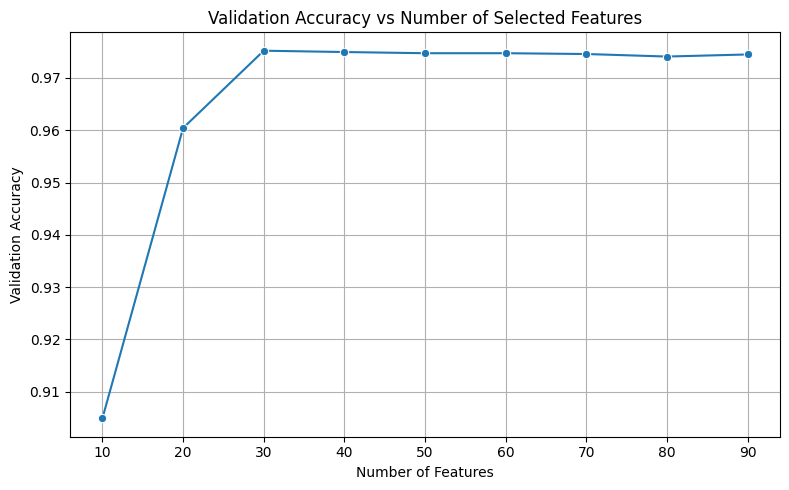

In [15]:
results_df = pd.DataFrame(results, columns=['num_features', 'val_accuracy'])
plt.figure(figsize=(8,5))
sns.lineplot(data=results_df, x='num_features', y='val_accuracy', marker='o')
plt.title("Validation Accuracy vs Number of Selected Features")
plt.xlabel("Number of Features")
plt.ylabel("Validation Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:
results_df

,num_features,val_accuracy
0,10,0.904901
1,20,0.960420
2,30,0.975209
3,40,0.974957
4,50,0.974731
5,60,0.974731
6,70,0.974577
7,80,0.974093
8,90,0.974494


In [ ]:
# Convert to list of dicts
results_dict = results_df.to_dict(orient='records')

# Save to local hard drive (same folder as script, or change path as needed)
output_path = 'results_chi_tuning.json'

with open(output_path, 'w') as f:
    json.dump(results_dict, f, indent=4)